<h1>Creación de Modelos Predictivos</h1>

<h2>Importar las Librerías Necesarias</h2>

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from narwhals import DataFrame
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

<h2>Modelos de Clasificación</h2>

In [2]:
dataset = fetch_ucirepo(id=468)
df_clasificacion = pd.concat([dataset.data.features, dataset.data.targets], axis=1)

<h3>Análisis de la Fuente de Datos</h3>
<p>Antes de iniciar el proceso de preparación es necesario conocer ciertos aspectos de la fuente de datos. En este caso se evaluaron los siguientes aspectos para saber el nivel de calidad de los datos existentes y si es necesario aplicar alguna transformación para realizar correcciones a alguno de los datos.</p>
<hr>

<b>Consideraciones de Análisis de Calidad de los Datos</b>
<ul>
    <li>Validar la existencia de los valores nulos.</li>
    <li>Validar que los tipos de datos sean consistentes con la información que almacenan.</li>
    <li>Validar que las variables categóricas que almacenan texto no tengan conflictos tipográficos.</li>
</ul>

In [3]:
print("Cantidad de valores vacios en cada columna:")
df_clasificacion.isna().sum()

Cantidad de valores vacios en cada columna:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [20]:
print("Información de los tipos de datos y valores no nulos:")
df_clasificacion.info()

Información de los tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 no

In [24]:
print("Validación de los valores de las variables categóricas:")
print("Valores de Month: ",df_clasificacion["Month"].unique())
print("Valores de VisitorType: ",df_clasificacion["VisitorType"].unique())

Validación de los valores de las variables categóricas:
Valores de Month:  <StringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str
Valores de VisitorType:  <StringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str


<b>Consideraciones de la Exploración Estadística</b>
<ul>
    <li>Visualizar la media, valor mínimo, valor máximo y el rango de valores que tienen algunas columnas numéricas importantes.</li>
    <li>Utilizar visualizaciones para conocer algunos patrones que pueden ser de interes.</li>
    <li>Validar la correlación entre las variables numéricas involucradas.</li>
    <li>Validar la distribución de los datos de la variable objetivo para conocer como los datos se distribuiran antes de realizar la estratificación en el modelo.</li>
</ul>

In [35]:
def descripcion_estadistica_numerica(df,columna):
    print("Media de",columna,":",df[columna].mean())
    print("Valor Mínimo de",columna,":",df[columna].min())
    print("Valor Máximo de",columna,":",df[columna].max())
    print("Rango de Valores en",columna,"(maximo - minimo):",df[columna].max() - df[columna].min())
    print("Desviación Estándar en",columna,df[columna].std())

In [38]:
descripcion_estadistica_numerica(df_clasificacion,"Administrative")

Media de Administrative : 2.3151662611516626
Valor Mínimo de Administrative : 0
Valor Máximo de Administrative : 27
Rango de Valores en Administrative (maximo - minimo): 27
Desviación Estándar en Administrative 3.3217841061569113


In [39]:
descripcion_estadistica_numerica(df_clasificacion,"ProductRelated")

Media de ProductRelated : 31.731467964314678
Valor Mínimo de ProductRelated : 0
Valor Máximo de ProductRelated : 705
Rango de Valores en ProductRelated (maximo - minimo): 705
Desviación Estándar en ProductRelated 44.47550330493652


In [40]:
descripcion_estadistica_numerica(df_clasificacion,"Informational")

Media de Informational : 0.5035685320356853
Valor Mínimo de Informational : 0
Valor Máximo de Informational : 24
Rango de Valores en Informational (maximo - minimo): 24
Desviación Estándar en Informational 1.270156425983391


Text(0.5, 1.0, 'Distribución de Revenue según VisitorType')

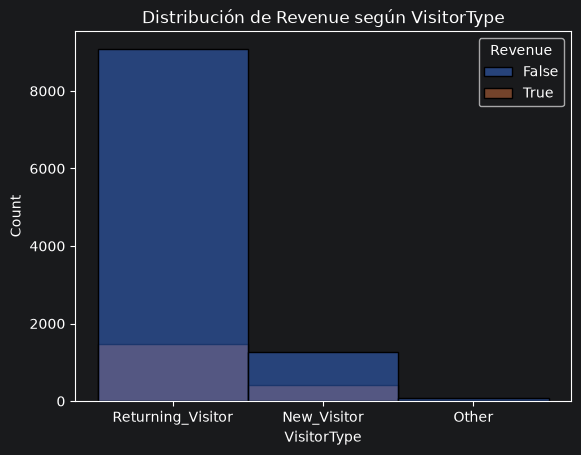

In [42]:
sns.histplot(data=df_clasificacion,x="VisitorType",hue="Revenue",bins=15).set_title("Distribución de Revenue según VisitorType")

Text(0.5, 1.0, 'Distribución de Revenue según Month')

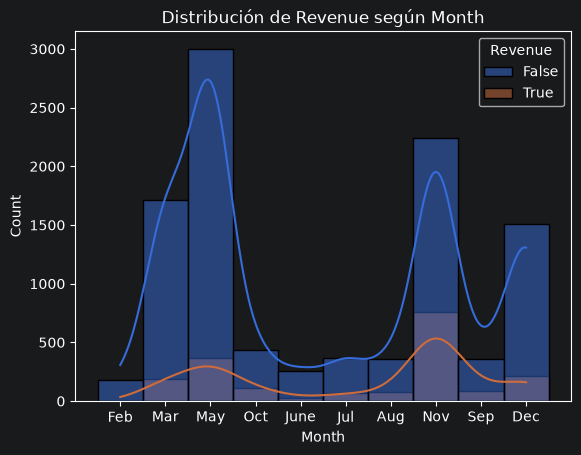

In [45]:
sns.histplot(data=df_clasificacion,x="Month",hue="Revenue",bins=15,kde=True).set_title("Distribución de Revenue según Month")

Text(0.5, 1.0, 'Duración en Páginas de Producto vs Tasa de Salida')

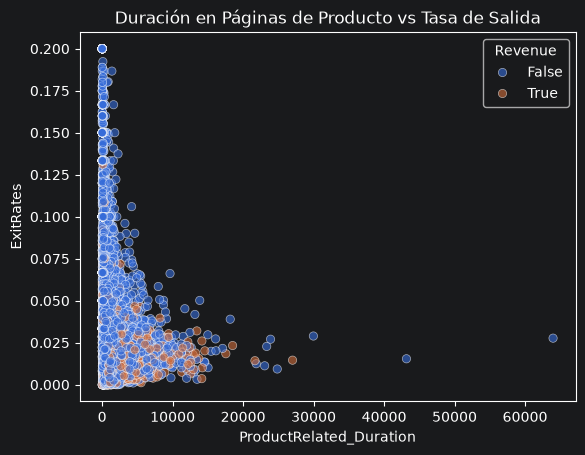

In [56]:
(sns.scatterplot(data=df_clasificacion, x='ProductRelated_Duration', y='ExitRates', hue='Revenue', alpha=0.6)
 .set_title("Duración en Páginas de Producto vs Tasa de Salida"))

Text(0.5, 1.0, 'Correlación entre métricas web')

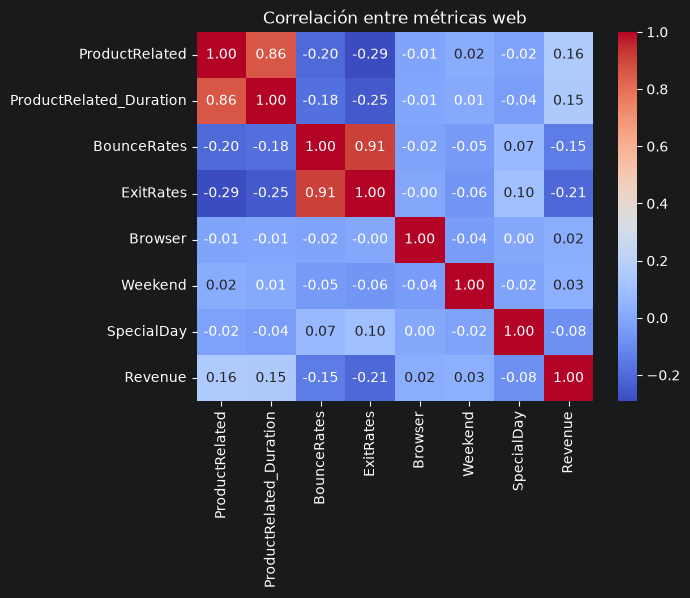

In [55]:
cols_num = ["ProductRelated", "ProductRelated_Duration","BounceRates","ExitRates","Browser","Weekend","SpecialDay","Revenue"]
sns.heatmap(df_clasificacion[cols_num].corr(), annot=True, cmap='coolwarm', fmt=".2f").set_title("Correlación entre métricas web")

<h3>Fundamentación del Modelo</h3>

In [58]:
X_clasificacion = df_clasificacion.drop(columns='Revenue')
y_clasificacion = df_clasificacion['Revenue'].astype(int)

In [59]:
X_trainclass, X_testclass, y_trainclass, y_testclass = train_test_split(X_clasificacion, y_clasificacion, test_size=0.2, random_state=42, stratify=y_clasificacion)

In [ ]:
sns.set_theme(style="whitegrid")

<h3>Preparación mínima para los modelos</h3>
<p>Siguiendo lo indicado en la práctica, las variables numéricas se escalan con <code>StandardScaler</code> y las categóricas se convierten en dummies (<code>OneHotEncoder</code>). Ambos pasos se incluyen dentro de un <code>Pipeline</code> junto con el modelo, para que se ajusten solo con los datos de entrenamiento y, en la validación cruzada, se reajusten en cada fold (sin fuga de información). <code>OperatingSystems</code>, <code>Browser</code>, <code>Region</code> y <code>TrafficType</code> se tratan como categóricas porque son códigos, no cantidades.</p>

In [60]:
columnas_categoricas = ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
columnas_numericas = [c for c in X_clasificacion.columns if c not in columnas_categoricas]
print("Numéricas:", columnas_numericas)
print("Categóricas:", columnas_categoricas)

def crear_preprocesador():
    return ColumnTransformer(transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False), columnas_categoricas)
    ])

Numéricas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categóricas: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


<h3>Construcción de los Modelos</h3>
<p>Se construyen dos modelos con <code>scikit-learn</code> sobre la partición 80 % / 20 % estratificada realizada arriba (<code>stratify=y</code>, <code>random_state=42</code>):</p>
<ul>
    <li><b>Naive Bayes Gaussiano:</b> modelo probabilístico que asume independencia condicional entre variables y distribución normal en cada una. Es rápido y simple, pero esas suposiciones se violan aquí (variables correlacionadas, dummies binarias y distribuciones sesgadas).</li>
    <li><b>Árbol de Decisión:</b> particiona el espacio de variables con reglas del tipo "si <i>PageValues</i> &gt; x". Es interpretable y captura relaciones no lineales. Sin límites tiende a sobreajustarse, por eso se restringe con <code>max_depth=5</code> y <code>min_samples_leaf=20</code>.</li>
</ul>

In [61]:
modelo_nb = Pipeline([('prep', crear_preprocesador()), ('clf', GaussianNB())])
modelo_dt = Pipeline([('prep', crear_preprocesador()),
                      ('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42))])

modelo_nb.fit(X_trainclass, y_trainclass)
modelo_dt.fit(X_trainclass, y_trainclass)

pred_nb = modelo_nb.predict(X_testclass)
pred_dt = modelo_dt.predict(X_testclass)

<h3>Evaluación: Matrices de Confusión y Métricas</h3>
<p>Para una matriz de confusión con la clase 1 (compra) como positiva:</p>
<ul>
    <li><b>Exactitud</b> = (TP + TN) / (TP + TN + FP + FN)</li>
    <li><b>Precisión</b> = TP / (TP + FP)</li>
    <li><b>Recall</b> = TP / (TP + FN)</li>
    <li><b>F1</b> = 2 · Precisión · Recall / (Precisión + Recall)</li>
</ul>

In [62]:
def metricas_manuales(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1': f1}

def comparar_manual_vs_sklearn(nombre, y_real, y_pred):
    m = metricas_manuales(y_real, y_pred)
    sk = {'Accuracy': accuracy_score(y_real, y_pred), 'Precision': precision_score(y_real, y_pred),
          'Recall': recall_score(y_real, y_pred), 'F1': f1_score(y_real, y_pred)}
    tabla = pd.DataFrame({'Manual': {k: m[k] for k in sk}, 'scikit-learn': sk})
    tabla['Diferencia'] = (tabla['Manual'] - tabla['scikit-learn']).abs()
    print(f"=== {nombre} ===")
    print(f"TN={m['TN']}  FP={m['FP']}  FN={m['FN']}  TP={m['TP']}")
    display(tabla.round(4))
    return m

m_nb = comparar_manual_vs_sklearn("Naive Bayes", y_testclass, pred_nb)
m_dt = comparar_manual_vs_sklearn("Árbol de Decisión", y_testclass, pred_dt)

=== Naive Bayes ===
TN=302  FP=1782  FN=10  TP=372


,Manual,scikit-learn,Diferencia
Accuracy,0.2733,0.2733,0.0
Precision,0.1727,0.1727,0.0
Recall,0.9738,0.9738,0.0
F1,0.2934,0.2934,0.0


=== Árbol de Decisión ===
TN=1992  FP=92  FN=156  TP=226


,Manual,scikit-learn,Diferencia
Accuracy,0.8994,0.8994,0.0
Precision,0.7107,0.7107,0.0
Recall,0.5916,0.5916,0.0
F1,0.6457,0.6457,0.0


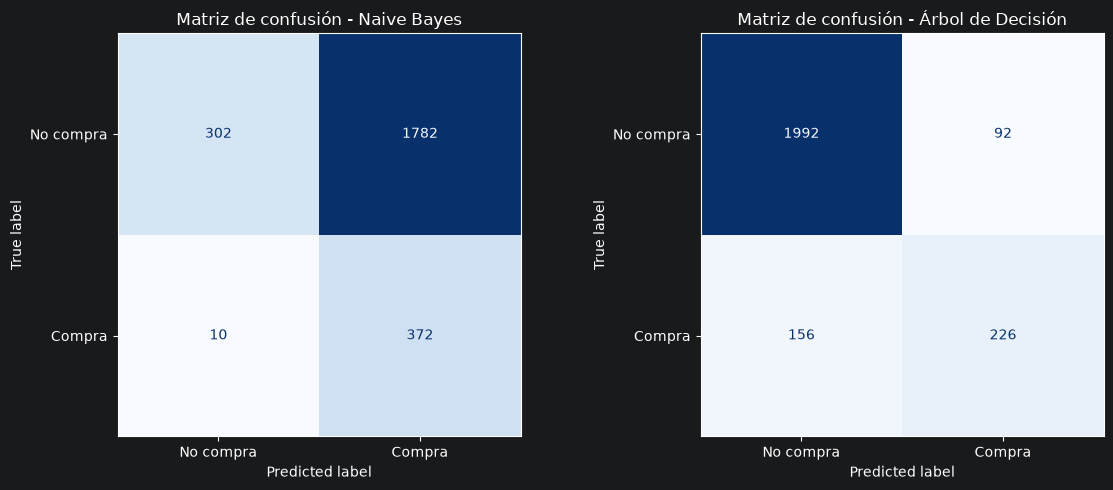

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre, pred in zip(axes, ['Naive Bayes', 'Árbol de Decisión'], [pred_nb, pred_dt]):
    ConfusionMatrixDisplay.from_predictions(y_testclass, pred, display_labels=['No compra', 'Compra'],
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión - {nombre}")
plt.tight_layout()
plt.show()

In [64]:
print("Naive Bayes\n", classification_report(y_testclass, pred_nb, target_names=['No compra', 'Compra']))
print("Árbol de Decisión\n", classification_report(y_testclass, pred_dt, target_names=['No compra', 'Compra']))

Naive Bayes
               precision    recall  f1-score   support

   No compra       0.97      0.14      0.25      2084
      Compra       0.17      0.97      0.29       382

    accuracy                           0.27      2466
   macro avg       0.57      0.56      0.27      2466
weighted avg       0.84      0.27      0.26      2466

Árbol de Decisión
               precision    recall  f1-score   support

   No compra       0.93      0.96      0.94      2084
      Compra       0.71      0.59      0.65       382

    accuracy                           0.90      2466
   macro avg       0.82      0.77      0.79      2466
weighted avg       0.89      0.90      0.90      2466



<h4>Interpretación de las matrices de confusión</h4>
<p><i>(Complétese con los números obtenidos al ejecutar.)</i> Guía para redactar:</p>
<ul>
    <li><b>TP:</b> sesiones con compra que el modelo detectó. <b>TN:</b> sesiones sin compra correctamente descartadas.</li>
    <li><b>FP:</b> el modelo predijo compra y no la hubo. <b>FN:</b> el modelo predijo "no compra" pero el usuario sí compró.</li>
    <li>Compárese cuántos FP y FN comete cada modelo: normalmente Naive Bayes tiende a marcar muchas sesiones como compra (más FP, recall alto pero precisión baja), mientras que el árbol es más equilibrado y con mayor exactitud.</li>
    <li>Recuérdese que un modelo que siempre predice "no compra" tendría una exactitud cercana al 84 %, por lo que la exactitud sola no basta; hay que mirar precisión, recall y F1 de la clase "compra".</li>
</ul>

<h3>Validación Cruzada Estratificada (5 folds)</h3>
<p>Se aplica sobre los datos de entrenamiento únicamente (el conjunto de prueba queda reservado). Al usar <code>Pipeline</code>, el escalado y las dummies se reajustan dentro de cada fold, evitando fuga de información.</p>

In [65]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}

resultados_cv = {}
for nombre, modelo in [('Naive Bayes', modelo_nb), ('Árbol de Decisión', modelo_dt)]:
    cv = cross_validate(modelo, X_trainclass, y_trainclass, cv=skf, scoring=scoring)
    resultados_cv[nombre] = cv
    print(f"--- {nombre} ---")
    por_fold = pd.DataFrame({m: cv[f'test_{m}'] for m in scoring}, index=[f'Fold {i}' for i in range(1, 6)])
    por_fold.loc['Media'] = por_fold.mean()
    por_fold.loc['Desv. est.'] = por_fold.iloc[:5].std()
    display(por_fold.round(4))

--- Naive Bayes ---


C:\Users\anton\Documents\C7\Inteligencia de Negocios\Activdad Evaluativa II\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\anton\Documents\C7\Inteligencia de Negocios\Activdad Evaluativa II\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,accuracy,precision,recall,f1
Fold 1,0.2681,0.1721,0.9803,0.2929
Fold 2,0.2889,0.1763,0.9803,0.2989
Fold 3,0.2737,0.1732,0.9803,0.2944
Fold 4,0.2879,0.1781,0.9935,0.3020
Fold 5,0.3103,0.1809,0.9803,0.3054
Media,0.2858,0.1761,0.9830,0.2987
Desv. est.,0.0164,0.0036,0.0059,0.0052


--- Árbol de Decisión ---


C:\Users\anton\Documents\C7\Inteligencia de Negocios\Activdad Evaluativa II\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\anton\Documents\C7\Inteligencia de Negocios\Activdad Evaluativa II\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,accuracy,precision,recall,f1
Fold 1,0.8799,0.6181,0.5836,0.6003
Fold 2,0.8991,0.7023,0.6033,0.6490
Fold 3,0.8976,0.7229,0.5475,0.6231
Fold 4,0.9072,0.7490,0.6046,0.6691
Fold 5,0.9113,0.7500,0.6393,0.6903
Media,0.8990,0.7085,0.5957,0.6464
Desv. est.,0.0121,0.0543,0.0336,0.0357


In [66]:
resumen_cv = pd.DataFrame({
    nombre: {m: f"{cv[f'test_{m}'].mean():.3f} ± {cv[f'test_{m}'].std():.3f}" for m in scoring}
    for nombre, cv in resultados_cv.items()
})
resumen_cv

,Naive Bayes,Árbol de Decisión
accuracy,0.286 ± 0.015,0.899 ± 0.011
precision,0.176 ± 0.003,0.708 ± 0.049
recall,0.983 ± 0.005,0.596 ± 0.030
f1,0.299 ± 0.005,0.646 ± 0.032


<h4>Comentario de la validación cruzada</h4>
<p><i>(Complétese con los resultados.)</i> Puntos a comentar: (1) si las medias de CV son similares a las métricas en prueba, el modelo generaliza bien; (2) una desviación estándar baja indica estabilidad entre folds; (3) si el árbol rinde mucho mejor en entrenamiento que en CV habría sobreajuste; (4) cuál modelo es más estable y en cuál métrica difieren más.</p>

<h3>Comparación de Modelos y Selección</h3>

,Accuracy,Precision,Recall,F1
Naive Bayes,0.2733,0.1727,0.9738,0.2934
Árbol de Decisión,0.8994,0.7107,0.5916,0.6457


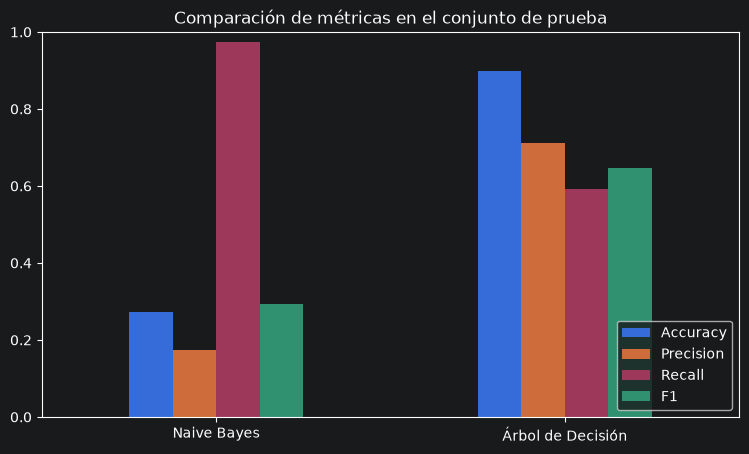

In [67]:
comparacion = pd.DataFrame({
    'Naive Bayes': {k: m_nb[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1']},
    'Árbol de Decisión': {k: m_dt[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1']}
}).T
display(comparacion.round(4))

comparacion.plot(kind='bar', figsize=(9, 5), rot=0)
plt.title("Comparación de métricas en el conjunto de prueba")
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

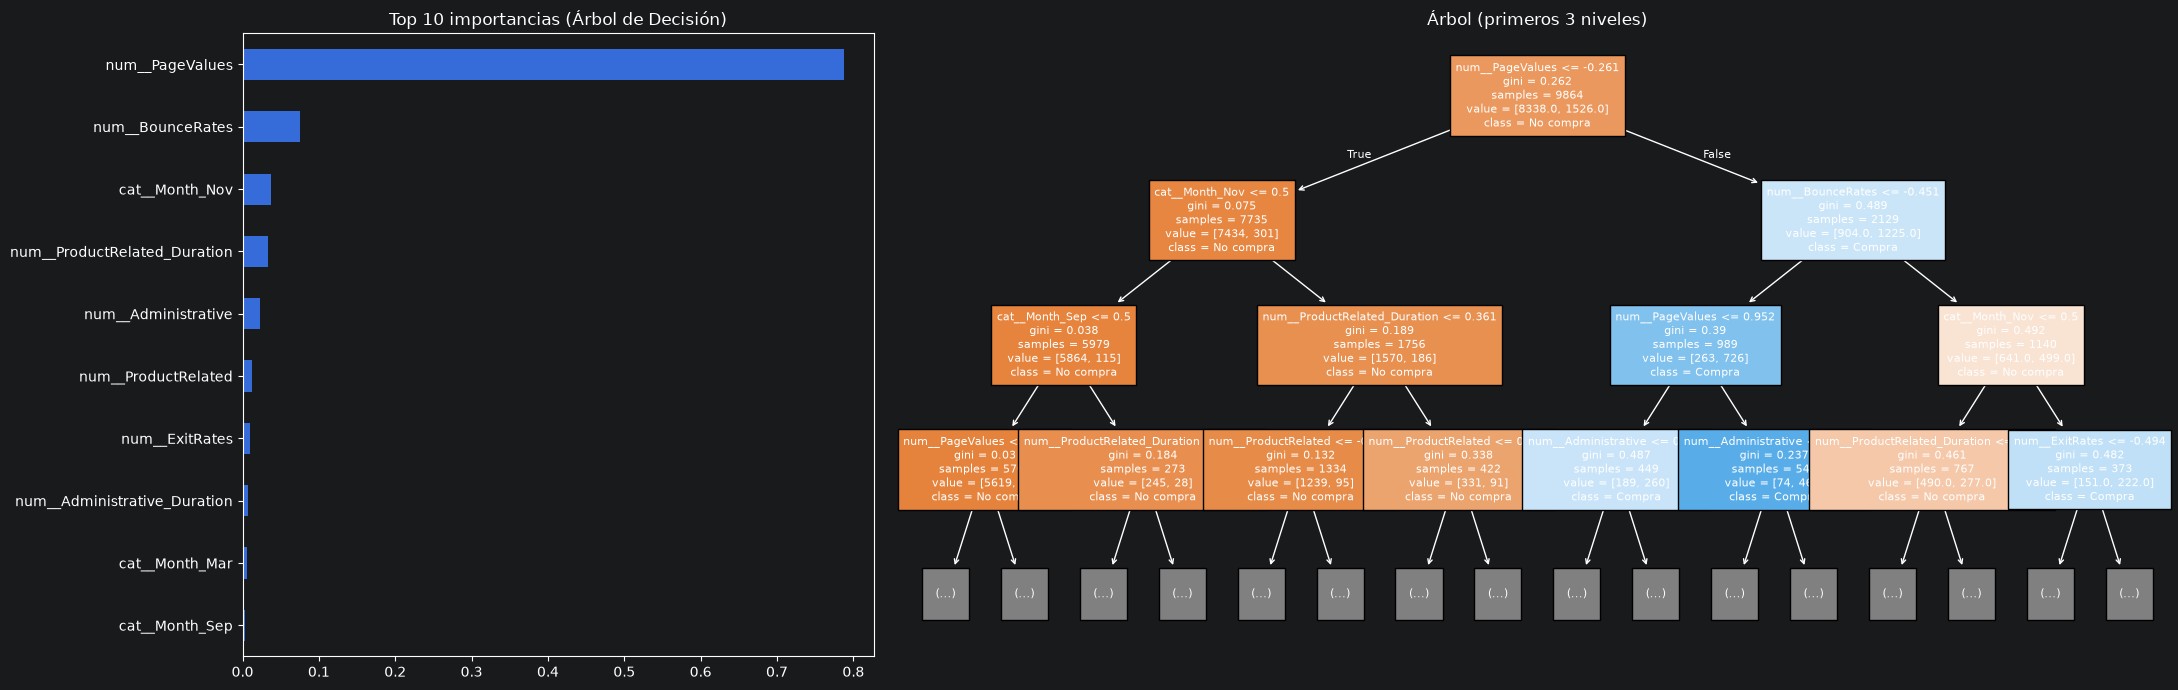

In [68]:
# Interpretabilidad del árbol: variables más importantes y estructura (primeros niveles)
arbol = modelo_dt.named_steps['clf']
nombres_feat = modelo_dt.named_steps['prep'].get_feature_names_out()
importancias = pd.Series(arbol.feature_importances_, index=nombres_feat).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={'width_ratios': [1, 2]})
importancias[::-1].plot(kind='barh', ax=axes[0], title="Top 10 importancias (Árbol de Decisión)")
plot_tree(arbol, max_depth=3, feature_names=nombres_feat, class_names=['No compra', 'Compra'],
          filled=True, fontsize=8, ax=axes[1])
axes[1].set_title("Árbol (primeros 3 niveles)")
plt.tight_layout()
plt.show()

<h4>Modelo seleccionado y justificación</h4>
<p><i>(Confirmar con los resultados obtenidos.)</i> Lo habitual con este dataset es que el <b>Árbol de Decisión</b> supere claramente a Naive Bayes en exactitud, precisión y F1, y sea más estable en la validación cruzada. Además, es interpretable: sus reglas muestran que <code>PageValues</code> es el factor dominante, lo que permite explicar la predicción a un equipo de negocio. Naive Bayes sufre porque su supuesto de independencia no se cumple (<code>BounceRates</code>/<code>ExitRates</code> correlacionadas, muchas variables dummy). Si Naive Bayes mostrara un recall notablemente más alto, habría que ponderarlo según el costo del negocio (ver siguiente pregunta). Se selecciona el modelo con mejor F1 y estabilidad en CV, justificándolo con los números de las tablas anteriores.</p>

<h3>Pregunta de Análisis</h3>
<p><b>¿Qué consecuencias podrían tener los falsos positivos y los falsos negativos en el contexto del problema? ¿Qué métrica es más importante y por qué?</b></p>
<ul>
    <li><b>Falso positivo (se predice compra y no ocurre):</b> la tienda gasta recursos en una sesión que no iba a convertir: descuentos innecesarios (pérdida de margen), chats o pop-ups intrusivos que pueden molestar al usuario, o campañas de remarketing mal dirigidas. También puede generar una visión demasiado optimista de la demanda (p. ej., planificar inventario de más).</li>
    <li><b>Falso negativo (se predice no compra y sí compra, o habría comprado con un pequeño incentivo):</b> se pierde la oportunidad de intervenir en usuarios con alta intención de compra (no ofrecer ayuda, envío gratis o recordatorios), con pérdida directa de ingresos. Si el modelo se usa para descartar sesiones, también se subestima la demanda.</li>
    <li><b>Métrica prioritaria:</b> dado que la clase de interés es minoritaria (~15 %), la exactitud es engañosa. Si las intervenciones son baratas (mostrar un banner, enviar un correo), el costo de un FN (venta perdida) supera al de un FP, por lo que priorizaríamos el <b>recall</b> de la clase "compra" sin dejar que la precisión se desplome. Si las intervenciones son costosas (descuentos fuertes), se priorizaría la <b>precisión</b>. Como equilibrio general, el <b>F1-score</b> de la clase positiva es la métrica de referencia más razonable. Con ese criterio, el umbral de decisión también puede ajustarse (p. ej. con <code>predict_proba</code>) según el costo real de cada error.</li>
</ul>